# Simulation

## Imports

In [2]:
import zarr
import numpy as np
import matplotlib.pyplot as plt

from src.move_object_utils import plot_dot_trajectory

## Data Exploration

In [3]:
store = zarr.open("pusht/pusht_cchi_v7_replay.zarr", mode="r")
print(store.tree())

/
├── data
│   ├── action (25650, 2) float32
│   ├── img (25650, 96, 96, 3) float32
│   ├── keypoint (25650, 9, 2) float32
│   ├── n_contacts (25650, 1) float32
│   └── state (25650, 5) float32
└── meta
    └── episode_ends (206,) int64

Explanation of each field:

$\mathbf{data/}$: Holds the actual time-series data. The first dimension (25650) is the number of timesteps (frames, samples). So each entry i across all arrays corresponds to the same time step.
- $\mathbf{action (25650, 2)}$: Likely the robot’s control commands at each step. Shape (2,) suggests 2 control values (e.g., linear & angular velocity, or x & y force).
- $\mathbf{img (25650, 96, 96, 3)}$: RGB images of size 96×96. 25,650 frames in total (matches timesteps). Shape matches height × width × channels.
- $\mathbf{keypoint (25650, 9, 2)}$: Probably 9 tracked points per frame, each with (x, y) coordinates. Example: object corners, fingertip positions, or visual features.
- $\mathbf{n\_contacts (25650, 1)}$: Number of contacts (e.g., how many fingers/links are touching an object).Shape (1,) per timestep → just a scalar.
- $\mathbf{state (25650, 5)}$: Low-dimensional state representation (e.g., joint angles, end-effector pose, sensor values). Each row has 5 floats.

$\mathbf{meta/}$: Metadata describing how data is organized.
- $\mathbf{episode\_ends (206,)}$: Marks the indices where episodes end. We have 206 episodes total.

In [4]:
images = store["data/img"]
images_np = images[0:162]

actions = store["data/action"] 
actions_np = actions[:162]

keypoints = store["data/keypoint"]
keypoints_np = keypoints[:162]

ncontacts = store["data/n_contacts"]
ncontacts_np = ncontacts[:162]

state = store["data/state"]
state_np = state[:162]

endpoints = store["meta/episode_ends"]
print(np.array(endpoints))

[  161   279   420   579   738   895   964  1133  1213  1347  1535  1684
  1824  1949  2056  2209  2335  2437  2523  2598  2740  2855  2964  3074
  3172  3305  3463  3575  3682  3797  3881  3976  4124  4244  4386  4529
  4671  4792  4978  5077  5216  5289  5425  5543  5670  5822  5905  6014
  6152  6235  6304  6377  6513  6686  6891  6997  7102  7185  7303  7425
  7485  7635  7702  7842  7945  8111  8178  8282  8372  8522  8708  8842
  8990  9102  9220  9318  9407  9529  9705  9775  9892 10005 10099 10238
 10318 10429 10533 10648 10729 10867 10976 11077 11155 11219 11286 11393
 11583 11694 11762 11844 11961 12053 12167 12308 12445 12520 12646 12843
 12955 13100 13231 13329 13400 13549 13714 13811 13989 14105 14207 14328
 14393 14530 14649 14854 15002 15161 15332 15473 15569 15725 15877 16060
 16215 16346 16469 16572 16697 16789 16975 17080 17192 17378 17500 17646
 17779 17946 18049 18211 18289 18426 18539 18691 18845 18942 19041 19135
 19225 19339 19444 19538 19685 19822 19983 20059 20

In [6]:
from PIL import Image
images = Image.fromarray(images_np[0].astype('uint8'))

In [ ]:
for img in images:
    try:
        img.show()
    except:
        torch.cuda.empty_cache()
        continue

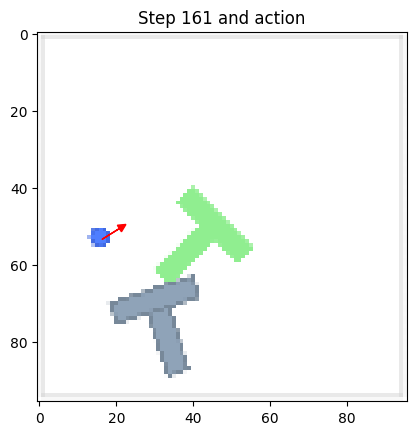

In [7]:
# Visualize using matplotlib
idx = 161

pos = state_np[:, :2]/512*96
act = actions_np[:, :2]/512*96

plt.imshow(images[idx]/255)
plt.arrow(pos[idx,0], pos[idx,1], act[idx,0]-pos[idx,0], act[idx,1]-pos[idx,1], head_width=2, head_length=2, fc='r', ec='r')
plt.title(f"Step {idx} and action")
plt.show()

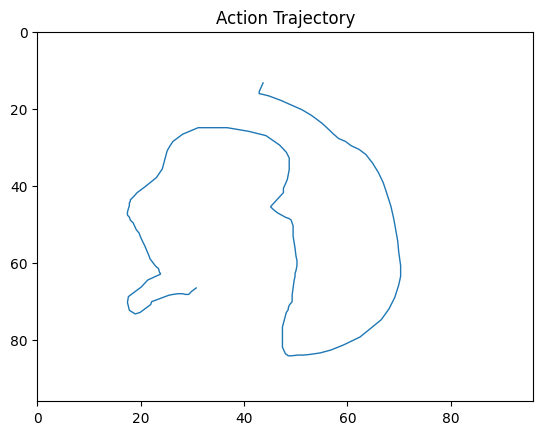

In [16]:
# Plot the action trajectory
plt.plot(actions_np[:,0]/512*96, actions_np[:,1]/512*96, linewidth=1)
plt.xlim(0,96)
plt.ylim(0,96)
plt.title("Action Trajectory")
plt.gca().invert_yaxis()
plt.show()

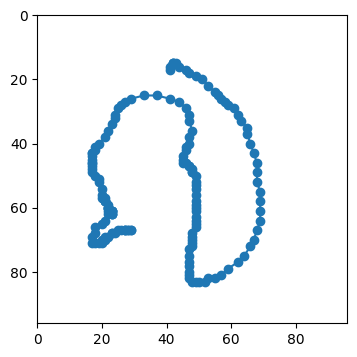

State position x ranges from 17.00 to 69.00
State position y ranges from 15.00 to 83.00


In [17]:
x, y = plot_dot_trajectory(images_np)

min_x_pos, max_x_pos = np.min(x), np.max(x)
min_y_pos, max_y_pos = np.min(y), np.max(y)
print(f"State position x ranges from {min_x_pos:.2f} to {max_x_pos:.2f}")
print(f"State position y ranges from {min_y_pos:.2f} to {max_y_pos:.2f}")
